# A practical guide to FOXES outputs

**Start with the question, then choose the output.** This notebook walks through a small, complete example: inspect turbine performance, summarize wind farms and clusters, sample the flow, make figures, and save files.

| Your question | Output to start with |
| --- | --- |
| What did each turbine produce? | `FarmResultsOutput` or `farm_results` |
| What are the capacity factor, efficiency and annual yield? | Request the corresponding variables in `FarmResultsOutput` |
| What is the weighted mean or total for my turbines, farms or clusters? | Farm results with `aggregate_states` / `aggregate_turbines` |
| What is the wind at specific locations? | `PointResultsOutput` through `calc_points` |
| Where are the turbines, and where does the wind come from? | `FarmLayoutOutput` and `RosePlotOutput` |
| What does a flow field look like? | `SliceData`, `FlowPlots2D`, or `FlowAnimation` |
| How do I save large calculations without collecting everything? | Farm/point count, calendar or chunk writers |

Run the cells in order. The example uses **six synthetic conditions, six turbines and the public packaged NREL 5 MW curve**; no downloads or private input files are needed. It uses the NumPy engine with bounded chunks. File-writing examples use temporary directories, which are cleaned automatically. Figures and the small GIF remain embedded in the notebook.

The probabilities describe an illustrative wind climate, not measured operation or a yield forecast.

## 1. Set up a small calculation

Choose the Python environment in which FOXES is installed. In a repository checkout, the test extra provides notebook execution support (`uv sync --extra test`).

In [1]:
%matplotlib inline
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import Image, display

import foxes
import foxes.constants as FC
import foxes.variables as FV
from foxes.models import outputs

/home/jonas/gits/wakes/foxes/foxes/input/states/create/wrf2foxes.py:5: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [2]:
weather = pd.DataFrame(
    {
        FV.WS: [7.0, 8.0, 9.0, 10.0, 11.0, 12.0],
        FV.WD: [270.0, 270.0, 280.0, 90.0, 90.0, 260.0],
        FV.WEIGHT: [0.10, 0.20, 0.20, 0.15, 0.20, 0.15],
    },
    index=pd.date_range("2020-01-01", periods=6, freq="12h"),
)
states = foxes.input.states.StatesTable(
    weather,
    output_vars=[FV.WS, FV.WD, FV.TI, FV.RHO],
    fixed_vars={FV.TI: 0.08, FV.RHO: 1.225},
)
display(weather.rename(columns={FV.WS: "Wind speed [m/s]", FV.WD: "Direction [deg]"}))

,Wind speed [m/s],Direction [deg],weight
2020-01-01 00:00:00,7.0,270.0,0.10
2020-01-01 12:00:00,8.0,270.0,0.20
2020-01-02 00:00:00,9.0,280.0,0.20
2020-01-02 12:00:00,10.0,90.0,0.15
2020-01-03 00:00:00,11.0,90.0,0.20
2020-01-03 12:00:00,12.0,260.0,0.15


The timestamps make calendar-file examples possible; **the explicit weights still define the climate probabilities**. Wind directions are meteorological: 270 degrees is wind **from the west**, and 90 degrees is from the east.

The six turbines belong to three named wind farms and two clusters. Membership is assigned when constructing turbines; aggregation does not infer it from position.

In [3]:
farm = foxes.WindFarm()
memberships = [
    ((0.0, 0.0), "West", "North"),
    ((600.0, 0.0), "West", "North"),
    ((1200.0, 0.0), "East", "North"),
    ((1800.0, 0.0), "East", "North"),
    ((0.0, 700.0), "South", "South"),
    ((600.0, 700.0), "South", "South"),
]
for index, (xy, wind_farm, cluster) in enumerate(memberships):
    farm.add_turbine(
        foxes.Turbine(
            xy,
            name=f"T{index + 1}",
            turbine_models=["NREL5MW"],
            wind_farm_name=wind_farm,
            cluster_name=cluster,
        ),
        verbosity=0,
    )

algo = foxes.algorithms.Downwind(
    farm, states, wake_models=["Jensen_linear_k004"], verbosity=0
)
engine = foxes.Engine.new(
    "numpy", chunk_size_states=2, chunk_size_points=100, verbosity=0
)

## 2. Calculate farm results and request performance metrics

All concrete output classes live in `foxes.models.outputs`. Pass a **model-book name**, an **output instance**, or a **list of either** to an algorithm:

- `calc_farm(outputs=...)` calculates turbine physics and runs the selected outputs.
- `calc_points(farm_results, points=..., outputs=...)` calculates results at supplied locations.
- `calc_outputs(outputs=..., farm_results=...)` reuses existing farm data. Point-dependent outputs can still calculate their requested flow grid.

By default, one selected output producing one value returns that value directly, even when selected as a one-entry list. Use **`ret_dict=True`** with any of these three methods to keep a **mapping of result names to values**, regardless of selection size. Farm and point result keys are fixed by their aggregation choices.

Here, one calculation collects all available farm fields and a state-mean performance dataset. Keeping `farm_results_all` is useful when subsequent point calculations need wake inputs outside the default field set. For large production jobs, collect only the fields you need.

**Derived variables are evaluated automatically when requested. Do not add a `TurbineEvaluation` turbine model manually.** A results class configured with `variables=None` alone does not request new metrics.

In [4]:
metrics = [FV.P, FV.AMB_P, FV.CAP, FV.AMB_CAPF, FV.CAPF, FV.EFF, FV.YLD]
with engine:
    results = algo.calc_farm(
        outputs=[
            "farm_results_all",
            outputs.FarmResultsOutput(variables=metrics, aggregate_states=True),
        ],
        ret_dict=True,
    )

farm_results = results[FC.FARM_RESULTS]
performance = farm_results
display(pd.DataFrame({name: dict(data.sizes) for name, data in results.items()}).T)
display(
    performance.isel({FC.STATE: 0})
    .to_dataframe()[[FV.P, FV.AMB_P, FV.CAPF, FV.EFF, FV.YLD]]
    .round(3)
)
assert all(variable in farm_results for variable in metrics)

,state,turbine
farm_results,6.0,6.0
mean_farm_results,NaN,6.0


,P,AMB_P,CAPF,EFF,YLD
turbine,,,,,
0,1187.200,1187.2,0.237,1.000,10.400
1,387.921,1187.2,0.078,0.327,3.398
2,163.135,1187.2,0.033,0.137,1.429
3,63.087,1187.2,0.013,0.053,0.553
4,1187.200,1187.2,0.237,1.000,10.400
5,387.921,1187.2,0.078,0.327,3.398


For this turbine type, `P`, `AMB_P` and `CAP` are in **kW**. Power units follow the turbine type; they are not universally kW. `AMB_P` is the no-wake reference power. `CAPF = P / CAP`, `AMB_CAPF = AMB_P / CAP` and `EFF = P / AMB_P` are **fractions**, not percentages.

`YLD` is in **GWh/a**: each state initially stores the yield obtained by annualizing that state's power for 8,760 hours. It is **not yet a probability-weighted contribution**. Use state aggregation to obtain a climate-weighted annual estimate. Requesting `P75`/`P90` additionally requires an explicit power uncertainty; this introductory example does not assume one.

The table above shows the first westerly condition. Turbines behind other turbines lose power relative to `AMB_P`. Result indices retain the original farm order, even when the wind reverses.

## 3. Summarize turbines, wind farms, clusters or the whole site

State and spatial aggregation are independent:

- `aggregate_states=True` uses normalized state probabilities separately for each entity.
- `aggregate_turbines=None` keeps turbines; `"wind_farm"`, `"cluster"` and `"all"` select spatial groups.
- Power, capacity and yield **sum** across turbines. Intensive fields **average**, directions use circular means, and ratios are recomputed from aggregated power/capacity.

This is why a plain `.mean()` over every dimension is not a suitable farm summary. The following summaries reuse `farm_results`; the turbine physics is not rerun.

In [5]:
groups = {
    FC.MEAN_FARM_RESULTS: None,
    FC.MEAN_FARMS_RESULTS: "wind_farm",
    FC.MEAN_CLUSTER_RESULTS: "cluster",
    FC.MEAN_TOTAL_FARM_RESULTS: "all",
}
with engine:
    summaries = algo.calc_outputs(
        farm_results=farm_results,
        outputs=[
            outputs.FarmResultsOutput(
                variables=metrics,
                aggregate_turbines=group,
                aggregate_states=True,
            )
            for group in groups.values()
        ],
    )

display(summaries[FC.MEAN_FARMS_RESULTS].to_dataframe()[metrics].round(3))
display(
    pd.DataFrame(
        [
            {"output": name, "dimensions": dict(data.sizes), **data.attrs}
            for name, data in summaries.items()
        ]
    ).set_index("output")
)
expected_power = np.average(performance[FV.P], axis=0, weights=weather[FV.WEIGHT])
assert np.isclose(
    summaries[FC.MEAN_TOTAL_FARM_RESULTS][FV.P].item(), expected_power.sum()
)

,P,AMB_P,CAP,AMB_CAPF,CAPF,EFF,YLD
wind_farm,,,,,,,
West,3603.945,6312.84,10000.0,0.631,0.360,0.571,31.571
East,4307.552,6312.84,10000.0,0.631,0.431,0.682,37.734
South,4969.324,6312.84,10000.0,0.631,0.497,0.787,43.531


,dimensions,power_unit,n_states,aggregate_states,n_turbines,aggregate_turbines
output,,,,,,
mean_farm_results,{'turbine': 6},kW,6,1,NaN,NaN
mean_farms_results,{'wind_farm': 3},kW,6,1,6.0,wind_farm
mean_cluster_results,{'cluster': 2},kW,6,1,6.0,cluster
mean_total_farm_results,{},kW,6,1,6.0,all


The reduced dataset's `n_states` and `n_turbines` attributes record **how many input entities contributed**, not the remaining dimension sizes. Counts appear for eliminated axes. The per-turbine mean therefore retains its turbine dimension without an aggregation `n_turbines` attribute.

### Select states before calculating a mean

`states_sel` takes state **labels**, not integer positions. Here we retain the first two conditions. Their probabilities sum to 0.30; aggregation renormalizes them, so the result describes the selected conditions rather than 30% of the full-climate result.

In [6]:
with engine:
    selected_mean = algo.calc_outputs(
        farm_results=farm_results,
        states_sel=list(weather.index[:2]),
        outputs=outputs.FarmResultsOutput(
            variables=metrics, aggregate_turbines="all", aggregate_states=True
        ),
    )

display(pd.Series({variable: selected_mean[variable].item() for variable in metrics}))
display(selected_mean.attrs)
assert selected_mean.attrs["n_states"] == 2

P            4665.865547
AMB_P        9458.800000
CAP         30000.000000
AMB_CAPF        0.315293
CAPF            0.155529
EFF             0.493283
YLD            40.872982
dtype: float64

{'n_states': 2,
 'n_turbines': 6,
 'aggregate_turbines': 'all',
 'aggregate_states': 1}

### Quick outputs with model-book shortcuts

Pass a model-book name directly as `outputs="..."` instead of constructing an output model. `calc_farm`, `calc_outputs` and `calc_points` accept these shortcuts; lists can mix names and instances.

| Shortcut | Quick result |
| --- | --- |
| `farm_results` | Ordinary fields for each state and turbine |
| `farm_results_P_mean` | Weighted ambient/waked mean power per turbine |
| `farms_results` | One result per state and wind farm |
| `cluster_results_mean` | Weighted summary per cluster |
| `total_results` | One whole-site result per state, combining all turbines |
| `total_results_analysis_mean` | Whole-site capacity, capacity factors and efficiency |
| `point_results_mean` | Weighted wind fields at each supplied point |
| `total_results_write_n4` | Whole-site NetCDF files with at most four input states each |
| `point_results_write_day` | One NetCDF file per calendar day |

All three spatially grouped farm families are available as plain names: `farms_results`, `cluster_results` and `total_results`. This table resolves actual presets without running another simulation:

In [7]:
preset_names = [
    "farm_results",
    "farm_results_analysis",
    "farms_results",
    "cluster_results",
    "total_results",
    "total_results_analysis_mean",
    "point_results_mean",
    "total_results_write_n4",
    "point_results_write_day",
]
display(
    pd.DataFrame(
        [
            {"preset": name, "class": type(algo.mbook.outputs[name]).__name__}
            for name in preset_names
        ]
    ).set_index("preset")
)

,class
preset,
farm_results,FarmResultsOutput
farm_results_analysis,FarmResultsOutput
farms_results,FarmResultsOutput
cluster_results,FarmResultsOutput
total_results,FarmResultsOutput
total_results_analysis_mean,FarmResultsOutput
point_results_mean,PointResultsOutput
total_results_write_n4,FarmResultsCountWriter
point_results_write_day,PointResultsPeriodWriter


#### Run one shortcut, or combine several

For a new calculation, use `algo.calc_farm(outputs="total_results_analysis_mean")` inside the engine context. Selecting `analysis` requests the derived metrics automatically; no evaluation turbine model is needed.

Both calls below reuse our earlier `farm_results` through `calc_outputs` without recalculating turbine physics. Reused data must already contain the requested fields: `calc_outputs` does not calculate missing turbine metrics. We requested the `analysis` metrics, including `AMB_CAPF`, in our original calculation. By default, one results class returns its dataset directly. Several results classes return a mapping keyed by their **dataset keys**, not their model-book names: `farm_results_P_mean` uses `FC.MEAN_FARM_RESULTS`, while `total_results_P_mean` uses `FC.MEAN_TOTAL_FARM_RESULTS`. Set `ret_dict=True` when a mapping is also needed for a single selection.

In [8]:
with engine:
    quick_total = algo.calc_outputs(
        farm_results=farm_results,
        outputs="total_results_analysis_mean",
    )
    quick_outputs = algo.calc_outputs(
        farm_results=farm_results,
        outputs=["farm_results_P_mean", "total_results_P_mean"],
    )
display(quick_total)
display(quick_outputs[FC.MEAN_FARM_RESULTS])
display(quick_outputs[FC.MEAN_TOTAL_FARM_RESULTS])

<xarray.Dataset> Size: 40B
Dimensions:   ()
Data variables:
    CAP       float64 8B 3e+04
    AMB_CAPF  float64 8B 0.6313
    CAPF      float64 8B 0.4294
    EFF       float64 8B 0.6801
    weight    float64 8B 1.0
Attributes:
    n_states:            6
    n_turbines:          6
    aggregate_turbines:  all
    aggregate_states:    1

<xarray.Dataset> Size: 480B
Dimensions:    (turbine: 6)
Coordinates:
  * turbine    (turbine) int64 48B 0 1 2 3 4 5
Data variables:
    AMB_P      (turbine) float64 48B 3.156e+03 3.156e+03 ... 3.156e+03 3.156e+03
    P          (turbine) float64 48B 1.984e+03 1.62e+03 ... 2.258e+03 2.711e+03
    weight     (turbine) float64 48B 1.0 1.0 1.0 1.0 1.0 1.0
    tname      (turbine) <U2 48B 'T1' 'T2' 'T3' 'T4' 'T5' 'T6'
    wind_farm  (turbine) <U5 120B 'West' 'West' 'East' 'East' 'South' 'South'
    cluster    (turbine) <U5 120B 'North' 'North' 'North' ... 'South' 'South'
Attributes:
    n_states:          6
    aggregate_states:  1

<xarray.Dataset> Size: 24B
Dimensions:  ()
Data variables:
    AMB_P    float64 8B 1.894e+04
    P        float64 8B 1.288e+04
    weight   float64 8B 1.0
Attributes:
    n_states:            6
    n_turbines:          6
    aggregate_turbines:  all
    aggregate_states:    1

#### Build a shortcut and find available names

For farm outputs the order is `<family>[_amb|_waked][_<fields>][_mean]`, then an optional writer suffix:

- **Family:** `farm_results`, `farms_results`, `cluster_results` or `total_results` chooses the turbine grouping.
- **Filter:** `_amb` or `_waked` selects one side of the ambient/waked fields; omit it for both.
- **Fields:** `_P` selects ambient/waked power and weights; `_wsP` adds rotor-effective wind speed. `_analysis` requests capacity, capacity factors and efficiency. `_all` retains available fields; it does not request every derived metric.
- **Mean:** `_mean` reduces the selected states using normalized weights. Omit it to keep states. Extensive fields still sum across turbines, and ratios are recomputed.
- **Writer:** `_write_n4`, `_write_chunks` or `_write_day` / `_week` / `_month` / `_year` chooses files instead of a collected dataset. For example, `total_results_waked_P_mean_write_month` writes monthly weighted whole-site power. Count/calendar means are computed separately for each file's input states. Chunk files follow engine chunks.

`farm_results_all` means **all available fields per turbine**; `total_results` means **all turbines combined**; `total_results_all` does both. Point shortcuts follow the same order, but use `point_results` and optionally `_aggregate_all` before `_mean` to average across points.

Discover presets and factory patterns with `algo.mbook.print_toc(subset=["outputs"], search="total_results")`. Resolve one with `algo.mbook.outputs[name]` to inspect or configure it **before** running, or use an explicit constructor for custom fields, filenames or axes. Writers produce files, not a dataset; combine a writer and results class when you need both. See the writing section below for temporary-directory recipes.

## 4. Check the layout and wind climate

Use constructor-defined plot outputs with existing data. The layout below makes it clear which turbines can sit in each other's wakes. A wind rose shows **weighted frequencies**, not the number of input rows.

Output constructors default to `show=False`. We display figures explicitly with Matplotlib in the notebook. Static plotting **presets** instead enable blocking display, so use instances or set their `show` flag to false for headless scripts.

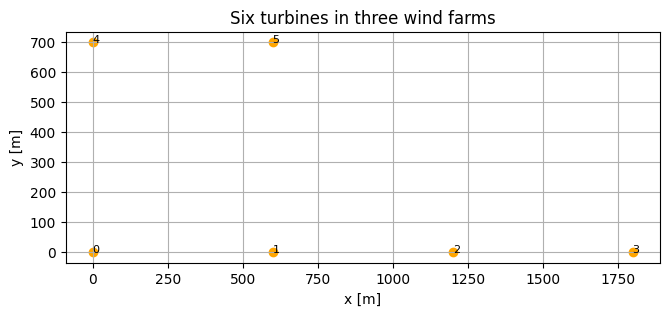

In [9]:
with engine:
    layout = algo.calc_outputs(
        farm_results=farm_results,
        outputs=outputs.FarmLayoutOutput(
            operation="get_figure",
            parameters={
                "figsize": (8, 3),
                "annotate": 1,
                "title": "Six turbines in three wind farms",
            },
        ),
    )
plt.show()
plt.close("all")

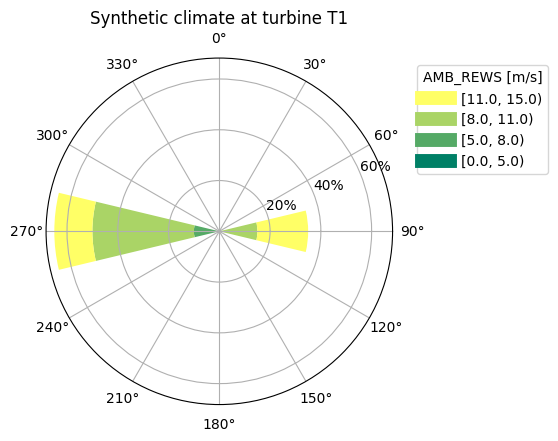

In [10]:
with engine:
    rose_axes, rose_data = algo.calc_outputs(
        farm_results=farm_results,
        outputs=outputs.RosePlotOutput(
            wd_sectors=12,
            ws_bins=[0, 5, 8, 11, 15],
            plot_pars={
                "figsize": (6, 4.5),
                "freq_delta": 20,
                "title": "Synthetic climate at turbine T1",
                "legend_pars": {"bbox_to_anchor": (1.05, 1), "loc": "upper left"},
            },
        ),
    )
plt.show()
plt.close("all")

Westerly conditions dominate this synthetic climate, but easterly conditions reverse the upstream/downstream ordering. The physical aggregation above accounts for all conditions rather than selecting one layout ordering.

## 5. Sample the flow along a line

`calc_points` accepts static coordinates shaped `(n_points, 3)` in metres, or state-dependent coordinates shaped `(n_states, n_points, 3)`. Point results use `(state, point)` dimensions and retain location coordinates.

`PointResultsOutput` mirrors `FarmResultsOutput`: `aggregate_states=True` creates a weighted state mean, while `aggregate_points="all"` averages locations. This example keeps the locations so we can draw a profile.

,state,point
point_results,6.0,80.0
mean_point_results,NaN,80.0


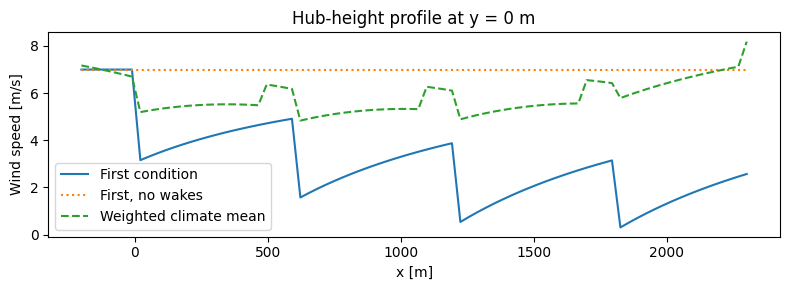

In [11]:
points = np.column_stack(
    [np.linspace(-200.0, 2300.0, 80), np.zeros(80), np.full(80, 90.0)]
)
with engine:
    point_outputs = algo.calc_points(
        farm_results,
        points=points,
        outputs=[
            "point_results_all",
            outputs.PointResultsOutput(
                variables=[FV.WS, FV.AMB_WS],
                aggregate_states=True,
            ),
        ],
    )
point_results = point_outputs[FC.POINT_RESULTS]
mean_points = point_outputs[FC.MEAN_POINT_RESULTS]
display(
    pd.DataFrame({name: dict(data.sizes) for name, data in point_outputs.items()}).T
)
assert FC.STATE not in mean_points.dims

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(points[:, 0], point_results[FV.WS].isel({FC.STATE: 0}), label="First condition")
ax.plot(
    points[:, 0],
    point_results[FV.AMB_WS].isel({FC.STATE: 0}),
    label="First, no wakes",
    linestyle=":",
)
ax.plot(points[:, 0], mean_points[FV.WS], label="Weighted climate mean", linestyle="--")
ax.set(xlabel="x [m]", ylabel="Wind speed [m/s]", title="Hub-height profile at y = 0 m")
ax.legend()
fig.tight_layout()
plt.show()
plt.close("all")

The solid and dotted curves compare wakes with the no-wake reference **for the same first condition**. The dashed curve describes a different quantity: the weighted mean of all six conditions.

## 6. Get a numerical slice or plot a flow map

`SliceData` returns numerical gridded data; `FlowPlots2D` renders it. Both support `xy`, `xz` and `yz` planes. The grid below is at the NREL turbine hub height of 90 m, with a deliberately modest point count.

For a normalized mean, explicitly use `aggregate_states=True`. Ordinary `reduction="mean"` retains its weighted-sum semantics, which matters when using only part of the climate.

In [12]:
grid = {"n_img_points": (40, 24), "z": 90.0}
with engine:
    mean_slice = algo.calc_outputs(
        farm_results=farm_results,
        outputs=outputs.SliceData(
            plane="xy",
            variables=[FV.WS, FV.WD],
            aggregate_states=True,
            data_format="xarray",
            grid_pars=grid,
        ),
    )
display(mean_slice.to_dataframe().head())
display(mean_slice.attrs)

WS          WD
y      x                           
-500.0 -500.000000  9.6  271.687651
       -428.205128  9.6  271.687651
       -356.410256  9.6  271.687651
       -284.615385  9.6  271.687651
       -212.820513  9.6  271.687651

{'z': 90.0, 'n_states': 6, 'aggregate_states': 1}

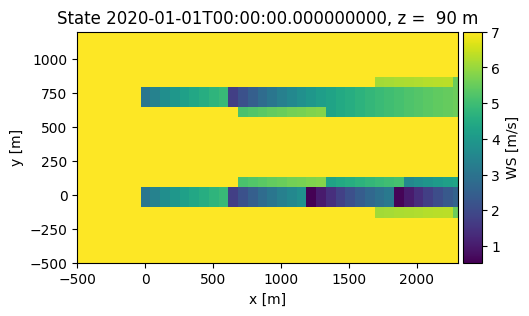

In [13]:
with engine:
    flow_figures = algo.calc_outputs(
        farm_results=farm_results,
        outputs=outputs.FlowPlots2D(
            plane="xy",
            var=FV.WS,
            reduction="states",
            states_isel=[0],
            grid_pars=grid,
            plot_pars={"figsize": (8, 3)},
        ),
    )
plt.show()
plt.close("all")

The map shows only the first condition, so its wakes should be interpreted with the corresponding wind speed and direction, not as the climate-mean map. `SliceData` above instead returns the weighted climate mean, including circular averaging of wind direction.

### Suppress images without requesting their point grids

Set `nofig=True` on an output to disable its image-producing mode before initialization and point calculations. This also suppresses animation and image files. A disabled output adds no result, so the call below returns `{}` rather than numerical plot data. No script-side filtering is needed.

Numerical results, data exports and `plot=False` modes remain enabled. Use `SliceData` or an explicit numerical mode when the data is needed without a figure. Setting `nofig=True` on an `OutputList` applies the same rule to its children.

In [ ]:
with engine:
    disabled_results = algo.calc_outputs(
        farm_results=farm_results,
        outputs=outputs.FlowPlots2D(nofig=True, grid_pars=grid),
        ret_dict=True,
    )
assert disabled_results == {}
display(disabled_results)

## 7. Write NetCDF files without an extra collected dataset

Farm and point writers use the same policies:

| Policy | Farm class | Point class | File boundaries |
| --- | --- | --- | --- |
| Count | `FarmResultsCountWriter` | `PointResultsCountWriter` | Exact state count, independent of engine chunks |
| Calendar | `FarmResultsPeriodWriter` | `PointResultsPeriodWriter` | `day`, `week`, `month` or `year`; datetime states required |
| Chunk | `FarmResultsChunkWriter` | `PointResultsChunkWriter` | One file per engine state chunk for farms; per state/target chunk for points |

This writes farm files with four states per file and daily point files. Both reuse data already calculated above. The two-state engine chunks do not determine the count-file boundaries. The writers accept the same aggregation options as the corresponding results classes.

In production, pass writers directly to `calc_farm` or `calc_points` to avoid keeping full results in memory. Add a results class to the same output list only when you also need a dataset. Writer-only selections do not fabricate one.

Point count/calendar writers assemble target tiles before writing a file; point chunk writers retain the engine's target tiling. Point files expose the internal `target` and `target_point` dimensions (one target point here), whereas collected public datasets use `point`.

To keep files, replace the temporary directory below with an output directory of your choice. Distinct filenames prevent repeated runs or scenarios from overwriting one another.

In [14]:
with TemporaryDirectory(prefix="foxes-output-tour-") as directory:
    destination = Path(directory)
    with engine:
        written = algo.calc_outputs(
            farm_results=farm_results,
            point_results=point_results,
            outputs=[
                outputs.FarmResultsCountWriter(
                    base_name=destination / "farm",
                    n_states_per_file=4,
                    variables=[FV.P, FV.AMB_P],
                ),
                outputs.PointResultsPeriodWriter(
                    base_name=destination / "points", period="day", variables=[FV.WS]
                ),
            ],
        )
    file_summary = []
    for filename in sorted(destination.glob("*.nc")):
        with xr.open_dataset(filename) as data:
            file_summary.append({"file": filename.name, **dict(data.sizes)})
    display(pd.DataFrame(file_summary).set_index("file"))
    assert len(list(destination.glob("farm_*.nc"))) == 2
    assert len(list(destination.glob("points_*.nc"))) == 3

,state,turbine,target,target_point
file,,,,
farm_000000.nc,4,6.0,NaN,NaN
farm_000001.nc,2,6.0,NaN,NaN
points_2020-01-01.nc,2,NaN,80.0,1.0
points_2020-01-02.nc,2,NaN,80.0,1.0
points_2020-01-03.nc,2,NaN,80.0,1.0


## 8. Save a small animation

`FlowAnimation` writes flow frames; `FlowTurbineAnimation` adds synchronized turbine traces. The same constructor-defined approach is used for both. GIF uses Pillow; MP4 additionally needs an external ffmpeg installation.

This two-frame GIF uses only the first two conditions. `base_name="wake.gif"` produces **`wake_WS.gif`**: the variable name is appended automatically. Encoding happens after the numerical chunks have been collected. Animation output writes files rather than returning a figure or dataset.

Animation verbosity 0 is silent, 1 announces creation, 2 adds writing/completion details, and 3 reports individual frames.

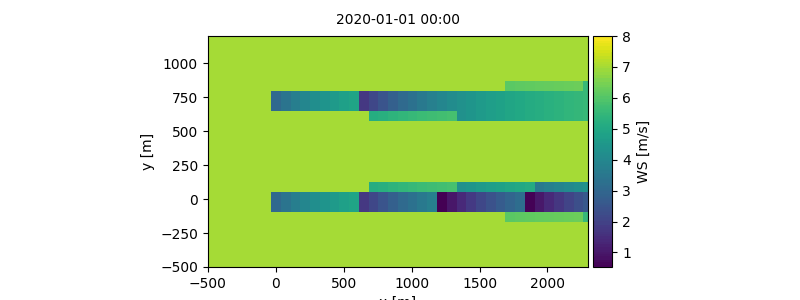

In [15]:
with TemporaryDirectory(prefix="foxes-output-animation-") as directory:
    with engine:
        algo.calc_outputs(
            farm_results=farm_results,
            outputs=outputs.FlowAnimation(
                out_dir=directory,
                base_name="wake.gif",
                variables=[FV.WS],
                plane="xy",
                states_isel=[0, 1],
                grid_pars=grid,
                fps=2,
                figsize=(8, 3),
                verbosity=0,
            ),
        )
    animation_file = Path(directory) / "wake_WS.gif"
    assert animation_file.is_file()
    display(Image(data=animation_file.read_bytes(), format="gif"))

## Choose your own recipe

1. **Start small:** `algo.calc_farm(outputs="farm_results")` for ordinary turbine results, or `outputs="total_results_analysis_mean"` for a quick whole-site performance summary.
2. **Ask for metrics:** configure `FarmResultsOutput(variables=[...])`; evaluation is automatic.
3. **Reduce at the output:** set `aggregate_states` and the domain's spatial aggregation option. Do not average power ratios or wind directions naively.
4. **Reuse what you calculated:** use `calc_outputs(farm_results=...)`, or supply `point_results` to avoid scientific point recalculation. A full grid output can still require new point calculations.
5. **Choose memory or files deliberately:** combine results classes and writers only when you need both. Use unique filenames for different cases.
6. **Keep the default field set distinct from all fields:** `farm_results_all` is convenient for follow-up point evaluation, but not a way to request every possible derived metric.

For more detailed examples, continue with [wind roses](wind_rose.ipynb), [time series](timeseries.ipynb), [dynamic wakes](dyn_wakes.ipynb), or the [model book](model_book.ipynb). The output API reference describes additional tables, turbine maps, multi-plane slices, curves and constructor options.